# Phase 5: Signal research and Grinold alphas

The baseline strategy (`main.ipynb`) found no edge, but it could not say **why**: momentum selects the
stocks, ARIMA supplies the views, and a max-Sharpe optimiser concentrates both into about 7 capped names.
This notebook separates the two questions a quant researcher would ask:

1. **Is there a premium to capture?** Each signal is tested on its own, before any portfolio is built:
   rank information coefficients (IC) at 1, 3, 6 and 12 months, sub-periods, quintile portfolios and
   Fama-MacBeth regressions, over **2003–2023** for the **full point-in-time S&P 500** and for the top 50.
2. **Does the portfolio use the signal?** Each signal is turned into an expected return the standard way,
   Grinold's **alpha = IC × volatility × z-score**, with the IC estimated only from past data, and fed into
   the same Black-Litterman / max-Sharpe allocation. The **transfer coefficient** measures how much of the
   signal reaches the weights.

**Data notes** (checked before building anything on the data):

* **Prices are split-adjusted:** no jumps on known split dates (AAPL 2014 and 2020, NVDA 2021, AMZN and GOOGL 2022, TSLA 2020).
* **`EPS` is empty in every row**, like `DVD_YLD_IND`, so value is measured by book-to-price only.
* **Book value is stamped at the fiscal period end, before it is published.** For example, AAPL's book value for
  the quarter ending 28 March 2020 appears on 30 March 2020, but Apple reported it on 30 April. Book value is
  therefore lagged **63 trading days (about 3 months)** before use.
* A stock that stops trading keeps its last price, as in the backtest engine. Returns are price returns.

Shared code (cleaning, universe, Black-Litterman, backtest engine, copied unchanged from `main.ipynb`, plus
the new signal and alpha functions) is in [`research.py`](research.py).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

import research as R

pd.set_option("display.float_format", "{:.4f}".format)
IMAGE_DIR = "images"

# Chart style, as in main.ipynb
SURFACE, INK, INK_2, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#e34948"
LIGHT_BLUE = "#86b6ef"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.titlelocation": "left", "axes.titlepad": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})
pct_axis = PercentFormatter(1.0, decimals=0)

def save_fig(fig, name):
    os.makedirs(IMAGE_DIR, exist_ok=True)
    fig.savefig(os.path.join(IMAGE_DIR, f"{name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

## 1. Reproduction check

`research.py` must reproduce the baseline before anything new is trusted: 12.2% CAGR, Sharpe 0.52,
453% turnover a year (2010–2023, 10 bps costs).

In [2]:
long_dates = R.period_ends("2010-01-01", "2023-12-31")
cache = R.arima_cache()
ctx = {}
for f in long_dates:
    u = R.universe(f)
    sig = R.momentum_signals(f, list(u.index))
    ctx[f] = {"universe": u, "sp500": R.universe(f, 10_000), "signals": sig,
              "views": pd.Series({t: cache[(f, t)]["view_annual"] for t in sig.index})}

def baseline(view_key="views"):
    def weights(f):
        c = ctx[f]
        sel = R.select_stocks(c["signals"], R.BASE["n_select"], R.BASE["rsi_max"])
        return R.black_litterman(f, list(sel.index), c["universe"], c[view_key])["weight"]
    return weights

check = {"Baseline": R.simulate(baseline(), long_dates, "2023-12-31")[0],
         "Cap-weight S&P 500": R.simulate(lambda f: ctx[f]["sp500"] / ctx[f]["sp500"].sum(), long_dates, "2023-12-31")[0]}
perf_check = R.performance(check)
assert abs(perf_check.loc["Baseline", "Sharpe"] - 0.52) < 0.005 and abs(perf_check.loc["Baseline", "CAGR"] - 0.122) < 0.0005
perf_check[["CAGR", "Volatility", "Sharpe", "Turnover / yr", "t-stat"]]

,CAGR,Volatility,Sharpe,Turnover / yr,t-stat
Baseline,0.1221,0.2044,0.5199,4.5315,0.5752
Cap-weight S&P 500,0.1108,0.1754,0.5170,0.0792,NaN


## 2. Signal panel

On the last trading day of every month from December 2002 to November 2023, every stock in that date's
S&P 500 snapshot gets eight signals, computed from data up to that day, and its forward returns.

| Signal | Definition | Expected sign (literature) |
|---|---|---|
| `mom_12_1` | return from 12 months to 1 month ago | + (Jegadeesh & Titman 1993) |
| `mom_6_1` | return from 6 months to 1 month ago | + |
| `high_52w` | price / 52-week high | + (George & Hwang 2004) |
| `rev_1m` | last month's return | − (short-term reversal) |
| `vol_1y` | 1-year daily volatility | − (low-volatility anomaly) |
| `size` | log market cap | − (size effect) |
| `book_to_price` | book value per share (lagged 3 months) / price | + (value) |
| `hist_mean` | mean monthly log return over all history (at least 36 months) | the ARIMA views in `main.ipynb` are mostly this |

In [3]:
panel_path = os.path.join(R.CACHE_DIR, "panel_monthly.pkl")
if os.path.exists(panel_path):
    panel = pd.read_pickle(panel_path)
else:
    panel = R.build_panel(R.period_ends("2003-01-01", "2023-12-31", "M"))
    panel.to_pickle(panel_path)
top = panel[panel.rank_cap <= R.UNIVERSE_SIZE]
dates_m = panel.index.get_level_values("date").unique()
print(f"{len(dates_m)} month-ends, {dates_m[0].date()} to {dates_m[-1].date()}; "
      f"{panel.groupby(level='date').size().mean():.0f} stocks a month on average (top 50: {top.groupby(level='date').size().mean():.0f})")

252 month-ends, 2002-12-31 to 2023-11-30; 499 stocks a month on average (top 50: 50)


## 3. Information coefficients

The IC is the rank (Spearman) correlation between a signal and the next period's returns across stocks,
computed each month. A useful equity signal typically has an IC of 0.02–0.05. Returns over 3, 6 and 12
months overlap from one month to the next, so t-statistics use Newey-West standard errors with
lags = horizon − 1 (and at least 1).

In [4]:
HORIZONS = {"fwd_1m": 1, "fwd_3m": 3, "fwd_6m": 6, "fwd_12m": 12}
rows = {}
for uname, uni in {"S&P 500": panel, "Top 50": top}.items():
    for s in R.SIGNALS:
        for h, lag in HORIZONS.items():
            m, t, n = R.nw_mean(R.rank_ic(uni, s, h), max(lag - 1, 1))
            rows[(uname, s, h)] = {"IC": m, "t": t}
ic_table = pd.DataFrame(rows).T
ic_wide = ic_table["IC"].unstack(2)[list(HORIZONS)].round(3).astype(str) + " (" + ic_table["t"].unstack(2)[list(HORIZONS)].round(1).astype(str) + ")"
ic_wide

fwd_1m         fwd_3m         fwd_6m  \
S&P 500 book_to_price  -0.011 (-1.1)  -0.017 (-1.1)  -0.021 (-0.9)   
        high_52w       -0.002 (-0.1)  -0.001 (-0.0)    0.001 (0.0)   
        hist_mean        0.011 (1.2)    0.015 (1.1)    0.021 (1.0)   
        mom_12_1         0.004 (0.3)  -0.001 (-0.1)  -0.005 (-0.2)   
        mom_6_1          0.007 (0.6)     0.01 (0.7)    0.015 (0.8)   
        rev_1m          -0.01 (-1.0)  -0.009 (-1.0)    0.002 (0.3)   
        size           -0.005 (-0.7)  -0.008 (-0.7)  -0.012 (-0.7)   
        vol_1y           0.006 (0.4)     0.01 (0.5)    0.007 (0.2)   
Top 50  book_to_price   -0.02 (-1.4)  -0.028 (-1.3)  -0.042 (-1.4)   
        high_52w         0.003 (0.2)    0.005 (0.2)    0.013 (0.5)   
        hist_mean        0.035 (2.3)    0.056 (2.5)    0.071 (2.4)   
        mom_12_1         0.018 (1.2)    0.019 (0.9)    0.022 (0.8)   
        mom_6_1          0.011 (0.8)    0.015 (0.8)     0.03 (1.3)   
        rev_1m         -0.009 (-0.7)  -0.008 (-0.6)    0.004 (0.3)   
        size           -0.006 (-0.6)  -0.008 (-0.5)   -0.01 (-0.4)   
        vol_1y           0.016 (0.8)    0.028 (1.1)    0.039 (1.1)   

                             fwd_12m  
S&P 500 book_to_price  -0.033 (-1.0)  
        high_52w         0.006 (0.2)  
        hist_mean        0.027 (1.0)  
        mom_12_1           0.0 (0.0)  
        mom_6_1          0.008 (0.4)  
        rev_1m           0.002 (0.2)  
        size           -0.014 (-0.6)  
        vol_1y         -0.012 (-0.3)  
Top 50  book_to_price  -0.058 (-1.3)  
        high_52w         0.017 (0.6)  
        hist_mean        0.079 (2.1)  
        mom_12_1         0.031 (1.0)  
        mom_6_1          0.026 (1.0)  
        rev_1m            0.01 (0.8)  
        size           -0.016 (-0.5)  
        vol_1y           0.049 (1.1)

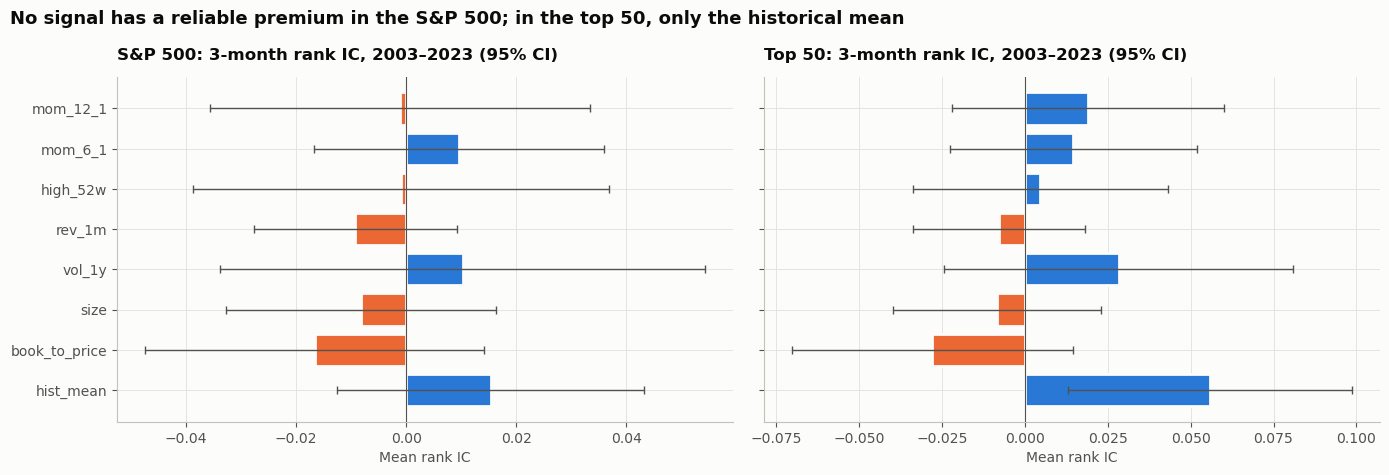

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, uname in zip(axes, ["S&P 500", "Top 50"]):
    d = ic_table.loc[uname].xs("fwd_3m", level=1)
    se = d["IC"] / d["t"]
    order = list(R.SIGNALS)[::-1]
    ax.barh(order, d.loc[order, "IC"], xerr=1.96 * se.loc[order], color=[BLUE if v > 0 else ORANGE for v in d.loc[order, "IC"]],
            edgecolor=SURFACE, linewidth=2, error_kw={"ecolor": INK_2, "elinewidth": 1, "capsize": 3})
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set_title(f"{uname}: 3-month rank IC, 2003–2023 (95% CI)")
    ax.set_xlabel("Mean rank IC")
fig.suptitle("No signal has a reliable premium in the S&P 500; in the top 50, only the historical mean",
             x=0.01, ha="left", fontsize=13, fontweight="semibold")
plt.tight_layout()
save_fig(fig, "phase5_ic")

### Sub-periods

The same 3-month IC in three 7-year periods. A real premium should not depend on one period.

In [6]:
PERIODS = {"2003–2009": ("2002-12-31", "2009-12-31"), "2010–2016": ("2010-01-01", "2016-12-31"),
           "2017–2023": ("2017-01-01", "2023-12-31")}
sub = {}
for uname, uni in {"S&P 500": panel, "Top 50": top}.items():
    for s in R.SIGNALS:
        ic = R.rank_ic(uni, s, "fwd_3m")
        for p, (a, b) in PERIODS.items():
            m, t, _ = R.nw_mean(ic.loc[a:b], 2)
            sub[(uname, s, p)] = f"{m:+.3f} ({t:+.1f})"
pd.Series(sub).unstack(2)[list(PERIODS)]

2003–2009      2010–2016      2017–2023
S&P 500 book_to_price  +0.024 (+0.9)  -0.013 (-0.6)  -0.063 (-2.0)
        high_52w       -0.024 (-0.7)  +0.004 (+0.1)  +0.018 (+0.6)
        hist_mean      +0.003 (+0.1)  -0.011 (-0.6)  +0.056 (+2.0)
        mom_12_1       -0.020 (-0.6)  +0.010 (+0.4)  +0.006 (+0.2)
        mom_6_1        +0.021 (+0.8)  -0.017 (-0.8)  +0.025 (+1.2)
        rev_1m         -0.021 (-1.3)  -0.012 (-0.7)  +0.006 (+0.4)
        size           -0.040 (-1.7)  -0.009 (-0.6)  +0.025 (+1.1)
        vol_1y         +0.027 (+0.7)  -0.001 (-0.0)  +0.004 (+0.1)
Top 50  book_to_price  +0.027 (+0.7)  -0.021 (-0.6)  -0.092 (-2.5)
        high_52w       -0.016 (-0.5)  -0.012 (-0.4)  +0.044 (+1.2)
        hist_mean      +0.001 (+0.0)  +0.034 (+1.2)  +0.136 (+2.9)
        mom_12_1       -0.011 (-0.3)  -0.001 (-0.0)  +0.072 (+1.7)
        mom_6_1        +0.019 (+0.6)  -0.024 (-0.9)  +0.050 (+1.3)
        rev_1m         -0.041 (-2.1)  -0.004 (-0.2)  +0.023 (+0.8)
        size           -0.037 (-1.5)  -0.034 (-1.1)  +0.047 (+1.8)
        vol_1y         +0.013 (+0.3)  +0.027 (+0.6)  +0.046 (+1.0)

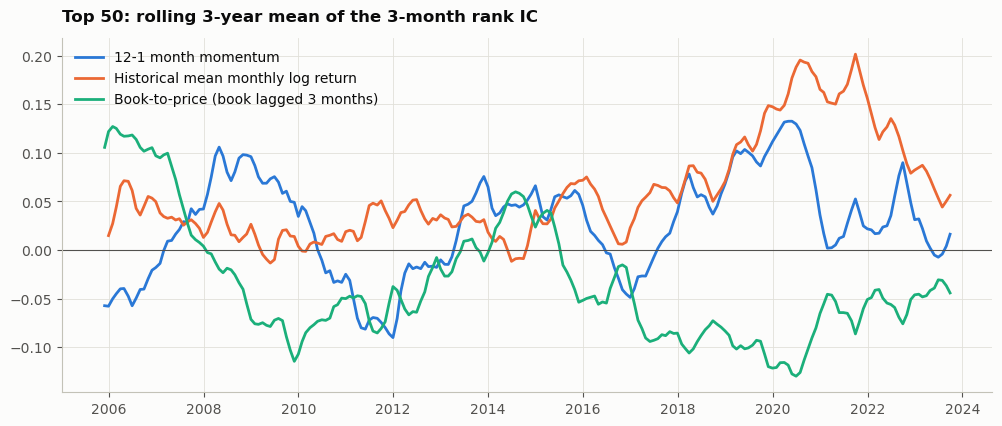

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.6))
for s, color in [("mom_12_1", BLUE), ("hist_mean", ORANGE), ("book_to_price", AQUA)]:
    r = R.rank_ic(top, s, "fwd_3m").rolling(36).mean().dropna()
    ax.plot(r.index, r.values, color=color, label=R.SIGNALS[s])
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_title("Top 50: rolling 3-year mean of the 3-month rank IC")
ax.legend(loc="upper left")
save_fig(fig, "phase5_rolling_ic")

## 4. Quintile portfolios

Each month, stocks are sorted into five equal groups by the signal and held for one month, equally weighted.
A real premium shows up as returns rising across the quintiles and a positive top-minus-bottom (Q5 − Q1) spread.

In [8]:
qrows, spreads = {}, {}
for uname, uni in {"S&P 500": panel, "Top 50": top}.items():
    for s in ["mom_12_1", "hist_mean", "book_to_price", "vol_1y"]:
        q = R.quintile_returns(uni, s, "fwd_1m")
        m, t, _ = R.nw_mean(q[5] - q[1], 1)
        qrows[(uname, s)] = {**{f"Q{i}": q[i].mean() * 12 for i in range(1, 6)}, "Q5 − Q1": m * 12, "t": t}
        spreads[(uname, s)] = q[5] - q[1]
quintiles = pd.DataFrame(qrows).T
quintiles.style.format("{:.1%}", subset=[f"Q{i}" for i in range(1, 6)] + ["Q5 − Q1"]).format("{:.2f}", subset=["t"])

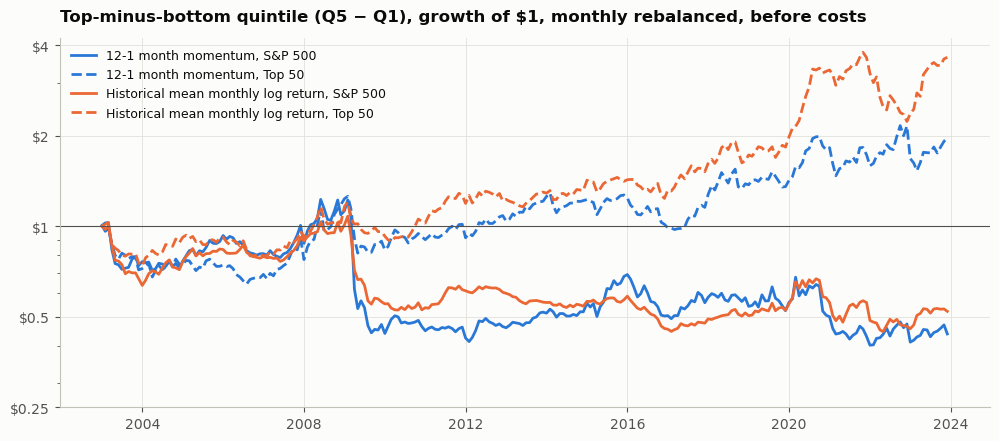

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.8))
for (uname, s), color, ls in [(("S&P 500", "mom_12_1"), BLUE, "-"), (("Top 50", "mom_12_1"), BLUE, "--"),
                              (("S&P 500", "hist_mean"), ORANGE, "-"), (("Top 50", "hist_mean"), ORANGE, "--")]:
    c = (1 + spreads[(uname, s)].fillna(0)).cumprod()
    ax.plot(c.index, c.values, color=color, ls=ls, label=f"{R.SIGNALS[s]}, {uname}")
ax.axhline(1, color=INK_2, lw=0.8)
ax.set_yscale("log")
ax.set_yticks([0.25, 0.5, 1, 2, 4])
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:g}"))
ax.set_title("Top-minus-bottom quintile (Q5 − Q1), growth of $1, monthly rebalanced, before costs")
ax.legend(loc="upper left", fontsize=9)
save_fig(fig, "phase5_quintile_spreads")

## 5. Fama-MacBeth regressions

Each month, next month's return is regressed on six signals at once (each winsorised at 1% / 99% and
standardised), so each coefficient is the return for a one-standard-deviation higher signal **holding the
others fixed**. The coefficients are averaged over the 251 months, with Newey-West t-statistics (3 lags).
Momentum (6-1) and the 52-week high are left out because they overlap heavily with 12-1 momentum.

In [10]:
FM_SIGNALS = ["mom_12_1", "rev_1m", "vol_1y", "size", "book_to_price", "hist_mean"]
fm_rows = {}
for uname, uni in {"S&P 500": panel, "Top 50": top}.items():
    fm = R.fama_macbeth(uni, FM_SIGNALS, "fwd_1m")
    for s in FM_SIGNALS:
        m, t, n = R.nw_mean(fm[s], 3)
        fm_rows[(uname, s)] = {"% per month per 1 sd": 100 * m, "t": t, "months": n}
fm_table = pd.DataFrame(fm_rows).T
fm_table.style.format({"% per month per 1 sd": "{:+.3f}", "t": "{:+.2f}", "months": "{:.0f}"})

In [11]:
# How the signals relate to each other in the top 50 (average monthly rank correlation)
top[FM_SIGNALS].groupby(level="date").corr(method="spearman").groupby(level=1).mean().loc[FM_SIGNALS, FM_SIGNALS].round(2)

,mom_12_1,rev_1m,vol_1y,size,book_to_price,hist_mean
mom_12_1,1.0000,0.0000,0.0600,0.0100,-0.2000,0.2700
rev_1m,0.0000,1.0000,0.0400,-0.0100,-0.0700,0.0900
vol_1y,0.0600,0.0400,1.0000,-0.1300,0.0900,0.0300
size,0.0100,-0.0100,-0.1300,1.0000,0.0200,0.0100
book_to_price,-0.2000,-0.0700,0.0900,0.0200,1.0000,-0.3500
hist_mean,0.2700,0.0900,0.0300,0.0100,-0.3500,1.0000


## 6. From signal to expected return: Grinold alphas

Grinold & Kahn's rule turns a score into an expected return that is already shrunk for the signal's skill:

$$\alpha_i = \text{IC} \times \sigma_i \times z_i$$

where $z_i$ is the stock's winsorised, standardised score and $\sigma_i$ its volatility. With quarterly
holding, the IC is the 3-month IC and $\sigma$ the quarterly volatility ($\sigma_{\text{annual}}/2$), so the
annual alpha is $2 \times \text{IC} \times \sigma_{\text{annual}} \times z$. A signal with no skill gets
alpha near zero and the portfolio stays close to the market.

* **IC estimated point in time.** On each rebalance date, the IC is the mean of the realised top-50
  3-month ICs whose returns are already known (formation at least 3 months earlier), from January 2003.
  At least 24 months are required.
* **Expected returns:** $\mu = \pi + \alpha$, where $\pi$ is the equilibrium prior of **all 50 universe
  stocks** (the baseline uses only the 25 selected names as its "market"). Because the alpha is already
  shrunk by the IC, it is not shrunk again with a Black-Litterman $\Omega$.
* **Same optimiser as the baseline:** max-Sharpe, long-only, at most 20% per stock, Ledoit-Wolf covariance.
  No momentum pre-filter: all 50 stocks are eligible, and the signal enters only through alpha.
* **Transfer coefficient** (Clarke, de Silva & Thorley 2002): the correlation between active weights
  (× volatility) and alpha (÷ volatility). 1 means the portfolio expresses the signal perfectly.

Three signals: 12-1 momentum, the historical mean, and a composite (average of the two z-scores).

**Also tested: correcting the ARIMA views.** `main.ipynb` converts the forecast mean *log* return into an
annual return with $e^{4\hat m} - 1$. That is the median, not the expected return: it understates the
expected return by about $\sigma^2/2$, more for volatile stocks (about 4.5% a year at 30% volatility). The
corrected view is $e^{4\hat m + 2 s^2} - 1$, with $s$ the ARIMA forecast's standard error (from its 95% interval).

In [12]:
top = top.copy()
z = lambda s: top.groupby(level="date")[s].transform(R.winsor_z)
top["composite"] = (z("mom_12_1") + z("hist_mean")) / 2
ALPHA_SIGNALS = {"mom_12_1": "momentum 12-1", "hist_mean": "historical mean", "composite": "composite"}
ic3 = {s: R.rank_ic(top, s, "fwd_3m") for s in ALPHA_SIGNALS}
months = list(ic3["mom_12_1"].index)

def ic_hat(s, f, min_obs=24):
    k = months.index(f)
    past = ic3[s].iloc[:max(k - 2, 0)].dropna()        # formations up to f - 3 months are realised by f
    return past.mean() if len(past) >= min_obs else np.nan

# ARIMA views corrected from median to mean
for f in long_dates:
    sig = ctx[f]["signals"].index
    fc = pd.Series({t: cache[(f, t)]["fc_quarter"] for t in sig})
    se = pd.Series({t: (cache[(f, t)]["ci_high"] - cache[(f, t)]["ci_low"]) / (2 * 1.959964) for t in sig})
    ctx[f]["views_mean"] = np.exp(4 * fc + 2 * se ** 2) - 1

def grinold(s, diag):
    def weights(f):
        u, g = R.universe(f), top.loc[f]
        ich = ic_hat(s, f)
        if not np.isfinite(ich):
            return R.mean_variance_bl(f, list(u.index), u, None)["weight"]
        a = R.grinold_alpha(g[s].reindex(u.index), g["vol_1y"].reindex(u.index), ich)
        bl = R.mean_variance_bl(f, list(u.index), u, a)
        diag[f] = {"IC estimate": ich, "alpha sd (annual)": a.std(), "names held": (bl["weight"] > 0.001).sum(),
                   "transfer coefficient": R.transfer_coefficient(bl["weight"], u / u.sum(), a.reindex(bl.index).dropna(), bl["vol"])}
        return bl["weight"]
    return weights

def run_alpha_tests(start, with_arima):
    dates = R.period_ends(start, "2023-12-31")
    diags = {s: {} for s in ALPHA_SIGNALS}
    P = {}
    if with_arima:
        P["Baseline (momentum + ARIMA views)"] = baseline("views")
        P["Baseline, ARIMA views corrected to mean"] = baseline("views_mean")
    P["Prior only, all 50 (no alpha)"] = lambda f: R.mean_variance_bl(f, list(R.universe(f).index), R.universe(f), None)["weight"]
    for s, label in ALPHA_SIGNALS.items():
        P[f"Grinold alpha: {label}"] = grinold(s, diags[s])
    P["Cap-weight top 50"] = lambda f: R.universe(f) / R.universe(f).sum()
    P["Cap-weight S&P 500"] = lambda f: R.universe(f, 10_000) / R.universe(f, 10_000).sum()
    sims = {k: R.simulate(fn, dates, "2023-12-31") for k, fn in P.items()}
    curves = {k: v[0] for k, v in sims.items()}
    diag = pd.DataFrame({f"Grinold alpha: {ALPHA_SIGNALS[s]}": pd.DataFrame(d).T.mean() for s, d in diags.items()}).T
    return curves, {k: v[1] for k, v in sims.items()}, R.performance(curves), diag

COLS = ["CAGR", "Volatility", "Sharpe", "Max drawdown", "Turnover / yr", "Excess vs S&P", "IR", "t-stat"]
def show(perf):
    return perf[COLS].style.format("{:.1%}", subset=["CAGR", "Volatility", "Max drawdown", "Turnover / yr", "Excess vs S&P"]).format("{:.2f}", subset=["Sharpe", "IR", "t-stat"])

## 7. Backtest: 2010–2023

Same period, rebalance dates, costs (10 bps) and benchmarks as `main.ipynb`. As a check on the method,
the **prior-only** portfolio should come out close to cap-weighting the top 50: with no alpha, the
max-Sharpe portfolio of the equilibrium returns is the market portfolio.

In [13]:
curves_10, logs_10, perf_10, diag_10 = run_alpha_tests("2010-01-01", True)
show(perf_10)

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,IR,t-stat
Baseline (momentum + ARIMA views),12.2%,20.4%,0.52,-33.0%,453.2%,1.6%,0.15,0.58
"Baseline, ARIMA views corrected to mean",14.4%,21.1%,0.60,-32.9%,427.1%,3.6%,0.34,1.26
"Prior only, all 50 (no alpha)",11.4%,17.9%,0.53,-30.0%,25.4%,0.4%,0.10,0.39
Grinold alpha: momentum 12-1,9.7%,19.8%,0.42,-32.3%,344.0%,-0.8%,-0.10,-0.37
Grinold alpha: historical mean,13.3%,22.2%,0.54,-50.5%,144.1%,2.9%,0.27,1.01
Grinold alpha: composite,12.2%,21.5%,0.50,-38.5%,289.5%,1.8%,0.17,0.65
Cap-weight top 50,11.5%,17.9%,0.53,-30.0%,21.9%,0.5%,0.14,0.51
Cap-weight S&P 500,11.1%,17.5%,0.52,-33.6%,7.9%,0.0%,nan,nan


In [14]:
diag_10.style.format({"IC estimate": "{:.3f}", "alpha sd (annual)": "{:.1%}", "names held": "{:.1f}", "transfer coefficient": "{:.2f}"})

,IC estimate,alpha sd (annual),names held,transfer coefficient
Grinold alpha: momentum 12-1,0.003,0.8%,22.6,0.71
Grinold alpha: historical mean,0.029,1.9%,12.4,0.71
Grinold alpha: composite,0.023,1.6%,17.2,0.70


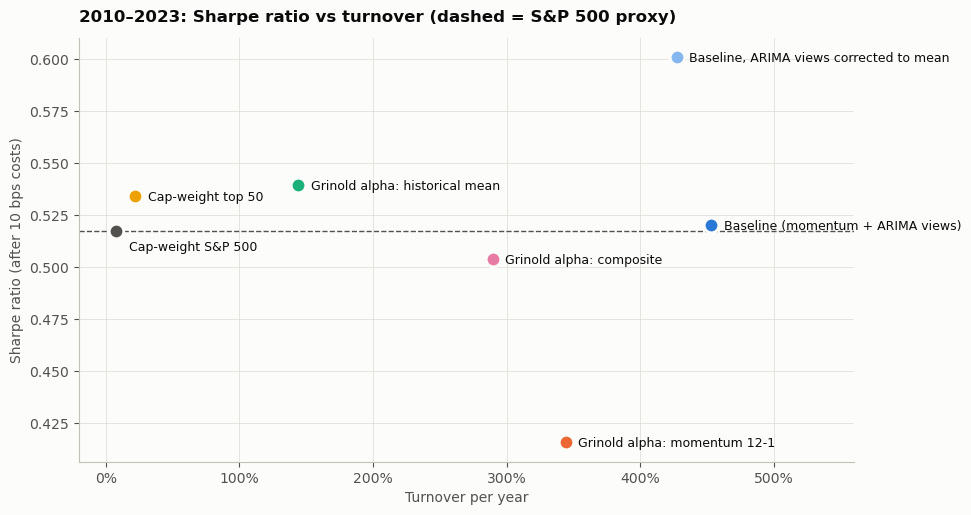

In [15]:
names = ["Baseline (momentum + ARIMA views)", "Baseline, ARIMA views corrected to mean", "Grinold alpha: momentum 12-1",
         "Grinold alpha: historical mean", "Grinold alpha: composite", "Cap-weight top 50", "Cap-weight S&P 500"]
colors = [BLUE, LIGHT_BLUE, ORANGE, AQUA, MAGENTA, YELLOW, INK_2]
fig, ax = plt.subplots(figsize=(10, 5.5))
for n, c in zip(names, colors):
    ax.scatter(perf_10.loc[n, "Turnover / yr"], perf_10.loc[n, "Sharpe"], s=110, color=c, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(n, (perf_10.loc[n, "Turnover / yr"], perf_10.loc[n, "Sharpe"]),
                xytext=(9, -14) if n == "Cap-weight S&P 500" else (9, -3), textcoords="offset points", fontsize=9)
ax.axhline(perf_10.loc["Cap-weight S&P 500", "Sharpe"], color=INK_2, ls="--", lw=1)
ax.xaxis.set_major_formatter(pct_axis)
ax.set_xlim(-0.2, 5.6)
ax.set_xlabel("Turnover per year")
ax.set_ylabel("Sharpe ratio (after 10 bps costs)")
ax.set_title("2010–2023: Sharpe ratio vs turnover (dashed = S&P 500 proxy)")
save_fig(fig, "phase5_alpha_backtest")

In [16]:
# Where the historical-mean alpha portfolio lost most: its largest drawdown and holdings at the time
c = curves_10["Grinold alpha: historical mean"]
dd = c / c.cummax() - 1
trough = dd.idxmin(); peak = c.loc[:trough].idxmax()
print(f"Largest drawdown {dd.min():.1%}: peak {peak.date()}, trough {trough.date()}")
w = logs_10["Grinold alpha: historical mean"]
w = w.loc[:, (w.columns >= "2021-06-01") & (w.columns <= "2022-12-31")]
w[w.max(axis=1) > 0.05].style.format("{:.0%}")

Largest drawdown -50.5%: peak 2021-11-04, trough 2022-10-14


,2021-06-30 00:00:00,2021-09-30 00:00:00,2021-12-31 00:00:00,2022-03-31 00:00:00,2022-06-30 00:00:00,2022-09-30 00:00:00,2022-12-30 00:00:00
AAPL,0%,0%,0%,0%,2%,8%,5%
ABBV,0%,0%,0%,5%,9%,5%,8%
AVGO,2%,3%,13%,7%,10%,12%,20%
GOOGL,0%,0%,5%,8%,14%,15%,8%
MA,20%,20%,20%,20%,20%,20%,20%
META,16%,16%,12%,3%,0%,0%,0%
NFLX,20%,20%,20%,20%,0%,0%,0%
NVDA,0%,0%,10%,16%,16%,13%,13%
PYPL,20%,20%,0%,0%,0%,0%,0%
TSLA,20%,20%,20%,20%,20%,20%,20%


## 8. Backtest: 2005–2023

Starting in 2005 adds the 2008 crisis and the 2009 rebound, when momentum famously crashed. The ARIMA
forecasts in `main.ipynb` only cover 2010–2023, so the baseline is not in this table.

In [17]:
curves_05, logs_05, perf_05, diag_05 = run_alpha_tests("2005-01-01", False)
show(perf_05)

,CAGR,Volatility,Sharpe,Max drawdown,Turnover / yr,Excess vs S&P,IR,t-stat
"Prior only, all 50 (no alpha)",7.6%,19.2%,0.32,-53.4%,26.7%,-0.1%,-0.04,-0.15
Grinold alpha: momentum 12-1,4.9%,20.2%,0.19,-57.6%,375.5%,-2.5%,-0.27,-1.20
Grinold alpha: historical mean,8.5%,22.3%,0.34,-52.6%,172.4%,1.4%,0.14,0.59
Grinold alpha: composite,7.7%,21.4%,0.31,-51.5%,302.2%,0.4%,0.04,0.19
Cap-weight top 50,7.7%,19.2%,0.32,-53.2%,23.9%,-0.0%,-0.01,-0.04
Cap-weight S&P 500,7.6%,19.4%,0.32,-56.0%,9.1%,0.0%,nan,nan


In [18]:
diag_05.style.format({"IC estimate": "{:.3f}", "alpha sd (annual)": "{:.1%}", "names held": "{:.1f}", "transfer coefficient": "{:.2f}"})

,IC estimate,alpha sd (annual),names held,transfer coefficient
Grinold alpha: momentum 12-1,-0.006,1.2%,20.8,0.69
Grinold alpha: historical mean,0.024,1.6%,16.5,0.72
Grinold alpha: composite,0.015,1.6%,17.6,0.70


## 9. Findings

All backtest figures are after 10 bps costs and exclude dividends.

**1. Momentum had no premium in the S&P 500 over 2003–2023.** No signal has a significant IC in the full
S&P 500 at any horizon (every |t| ≤ 1.2). For 12-1 momentum the 3-month IC is −0.001 (t −0.1), the
top-minus-bottom quintile earned −1.8% a year (t −0.41), and the Fama-MacBeth coefficient is −0.019% a
month (t −0.20). The momentum spread crashed in the 2009 rebound and never recovered.

**2. The historical-mean "skill" in the top 50 is the 2017–2023 growth rally.** It is the only signal with a
significant IC in the top 50 (0.056 at 3 months, t 2.5; quintile spread 7.4% a year, t 2.12), but the IC
is 0.001 in 2003–2009, 0.034 in 2010–2016 and 0.136 (t 2.9) in 2017–2023. Holding the other signals fixed
(Fama-MacBeth), it falls to t = 1.21. It is correlated −0.35 with book-to-price and +0.27 with momentum:
it favours long-run winners, which are growth stocks, in a period when growth beat value (top-50
book-to-price IC −0.092, t −2.5, in 2017–2023). This confirms the caveat in the README: it is not stable skill.

**3. Grinold alphas make the portfolio use the signal.** The transfer coefficient is about 0.70 for every
signal, against about 0.16 implied for the baseline, and the portfolio holds 12–23 names instead of a median
of 7. With no alpha, the same optimiser returns the market portfolio (Sharpe 0.53, the same as cap-weighting
the top 50), as it should.

**4. But there is little signal to transfer, and max-Sharpe overtrades it.** Estimated point in time, the
3-month ICs are small (momentum 0.003, historical mean 0.029), so alphas are small (standard deviation
0.8–1.9% a year). The max-Sharpe optimiser still turns them into large trades: the momentum alpha
portfolio turns over 344% a year for a Sharpe of 0.42. The historical-mean alpha reaches a Sharpe of 0.54
(t 1.01) but with a −50.5% drawdown from November 2021 to October 2022, holding Tesla and Mastercard at the
20% cap throughout (and Netflix until mid-2022): alpha scales with volatility, so the most volatile growth
stocks get the largest alphas.

**5. Since 2005, nothing beats cap-weighting.** Including 2008-09, both cap-weight benchmarks have a Sharpe of
0.32; the momentum alpha 0.19 (t −1.20) and the historical-mean alpha 0.34 (t 0.59).

**6. Correcting the ARIMA views helps, but is not significant.** Converting the forecasts to expected rather
than median returns raises the baseline's Sharpe from 0.52 to 0.60 and its CAGR from 12.2% to 14.4% (t 1.26).
This is a bug fix rather than a tuned setting, but its gain comes from removing a penalty on volatile stocks
in a period when volatile growth stocks did well.

**Answer.** The baseline's weak result is not only a portfolio-construction problem: large-cap US momentum
offered almost nothing to capture in 2003–2023. Fixing the construction (Grinold alphas) makes the portfolio
follow its signals, which exposes that the signals are weak and that an unconstrained max-Sharpe optimiser
overreacts to weak signals. The next step is benchmark-relative optimisation with a turnover penalty and a
tracking-error budget, using residual rather than total volatility.

**Limitations**
* Price returns only; `EPS` and dividends are empty in the data, so value is book-to-price alone.
* The IC used for alphas is estimated on the top 50 (50 stocks a month), so it is noisy.
* Alphas use total volatility; Grinold's rule calls for residual volatility, which needs a risk model.
* Quintile portfolios are equal-weighted and before costs. The risk-free rate is a constant 3%, as in `main.ipynb`.
